<a href="https://colab.research.google.com/github/raditya12/MachineLearning/blob/master/MachineLearnJS5TugasPrak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [12]:
iris = load_iris()

X = iris.data
y_true = iris.target

print("Jumlah data :", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Label asli  :", iris.target_names)

Jumlah data : 150
Jumlah fitur: 4
Label asli  : ['setosa' 'versicolor' 'virginica']


In [13]:
##standarisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
##clustering DBSCAN
hdbscan = HDBSCAN(
    min_cluster_size=5,
    copy=True
)

labels = hdbscan.fit_predict(X_scaled)

In [15]:
##hitung cluster dan noise
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise  :", n_noise)

Jumlah cluster: 2
Jumlah noise  : 2


In [16]:
##jumlah data di cluster
unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    if label == -1:
        print("Noise:", count)
    else:
        print(f"Cluster {label}: {count}")

Noise: 2
Cluster 0: 50
Cluster 1: 98


In [17]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(150, 2)


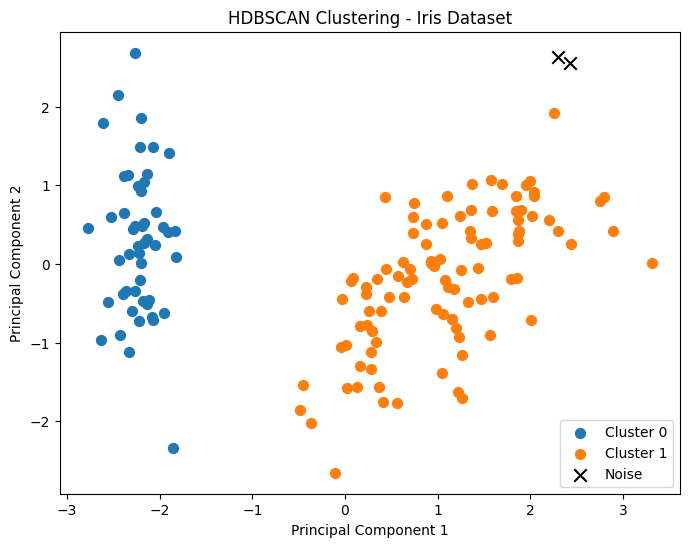

In [18]:
##visualisasi
plt.figure(figsize=(8, 6))

unique_labels = set(labels)

for label in unique_labels:

    mask = labels == label

    if label == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c='black',
            marker='x',
            s=80,
            label='Noise'
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=50,
            label=f'Cluster {label}'
        )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('HDBSCAN Clustering - Iris Dataset')
plt.legend()
plt.show()

In [19]:
##compare dengan label
df_hasil = pd.DataFrame({
    'Label Asli': iris.target_names[y_true],
    'Cluster HDBSCAN': labels
})

pd.crosstab(
    df_hasil['Label Asli'],
    df_hasil['Cluster HDBSCAN']
)

Cluster HDBSCAN,-1,0,1
Label Asli,,,
setosa,0,50,0
versicolor,0,0,50
virginica,2,0,48


In [20]:
ari = adjusted_rand_score(y_true, labels)

print(f"Adjusted Rand Index: {ari:.3f}")

Adjusted Rand Index: 0.564


# **Analisis Singkat**

Berdasarkan hasil clustering menggunakan HDBSCAN pada Iris Dataset, diperoleh 2 cluster dan 2 data yang dikategorikan sebagai noise. Hasil tersebut belum sepenuhnya sesuai dengan label asli Iris yang terdiri dari 3 kelas, yaitu Setosa, Versicolor, dan Virginica. HDBSCAN berhasil memisahkan seluruh data Setosa ke dalam satu cluster. Namun, data Versicolor dan sebagian besar Virginica digabungkan ke dalam cluster yang sama, sedangkan dua data Virginica dianggap sebagai noise. Hal ini menunjukkan bahwa karakteristik Setosa cukup berbeda dibandingkan dua spesies lainnya, sedangkan Versicolor dan Virginica memiliki karakteristik yang lebih saling berdekatan sehingga HDBSCAN tidak memisahkannya menjadi dua cluster berbeda pada konfigurasi yang digunakan. Nilai Adjusted Rand Index sekitar 0,564 menunjukkan bahwa hasil clustering memiliki kesesuaian sedang dengan label asli, tetapi belum dapat merepresentasikan ketiga kelas secara sempurna.